# 03 — Model Comparison, Decoupled Architectures & Statistical Validation


In [1]:
# ---- Shared configuration -------------------------------------------------
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
torch.manual_seed(42); np.random.seed(42)

DATA_PATH = "/kaggle/input/datasets/fahmidaalamtamim/dataset-recalculated/FINAL_PCF_DATASET_recalculated.xlsx"   # <-- adjust (e.g. /kaggle/input/.../FINAL_PCF_DATASET.xlsx)
PROCESSED = "/kaggle/input/datasets/fahmidaalamtamim/processed/processed_dataset (2).npz"


OUT_DIR = Path("/kaggle/working/output_model_comparison")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RESPONSES = ["real ewfd", "imag ewfd", "Aeff", "dispersion(y)",
             "non linearity(y)", "conf loss(y)"]
TARGETS = ["Ratio", "Shape", "No. of rings", "Anomaly position"]

N_AUG = 40; NOISE_FRAC = 0.02; N_FOLDS = 5
EPOCHS = 300; PATIENCE = 30; LR = 1e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


In [2]:
# ---- Load the processed dataset from Notebook 01 ---------------------------
z = np.load(PROCESSED, allow_pickle=True)
X = z["X"]; wavelengths = z["wavelengths"]; feat_names = list(z["feat_names"])
y = {t: z[f"y_{i}"] for i, t in enumerate(TARGETS)}
classes = {t: z[f"c_{i}"] for i, t in enumerate(TARGETS)}
n_classes = {t: len(classes[t]) for t in TARGETS}
n_wl = len(wavelengths)
print(f"{X.shape[0]} structures, {X.shape[1]} features ({len(RESPONSES)} responses x {n_wl} wavelengths)")
print("classes:", n_classes)

54 structures, 528 features (6 responses x 88 wavelengths)
classes: {'Ratio': 2, 'Shape': 3, 'No. of rings': 3, 'Anomaly position': 3}


## 3.1 Shared definitions (models, CV runners)

In [3]:
class MultiHeadInverseNet(nn.Module):
    def __init__(self, in_dim, n_classes, hidden=(128, 64), p_drop=0.1):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(),
                       nn.Dropout(p_drop)]
            d = h
        self.trunk = nn.Sequential(*layers)
        self.heads = nn.ModuleDict(
            {t.replace(".", "_"): nn.Linear(d, k) for t, k in n_classes.items()})

    def forward(self, x):
        z = self.trunk(x)
        return {t: head(z) for t, head in self.heads.items()}


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def augment(X, ys, n_copies, noise_frac, rng):
    stds = X.std(axis=0, keepdims=True) + 1e-12
    Xa = [X]
    for _ in range(n_copies):
        Xa.append(X + rng.normal(0, noise_frac, X.shape) * stds)
    Xa = np.vstack(Xa)
    ya = {t: np.tile(v, n_copies + 1) for t, v in ys.items()}
    return Xa, ya


def train_one(model, Xtr, ytr, Xva, yva, epochs=EPOCHS, patience=PATIENCE):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    ce = nn.CrossEntropyLoss()
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE)
    Xva_t = torch.tensor(Xva, dtype=torch.float32, device=DEVICE)
    ytr_t = {t: torch.tensor(v, dtype=torch.long, device=DEVICE)
             for t, v in ytr.items()}
    yva_t = {t: torch.tensor(v, dtype=torch.long, device=DEVICE)
             for t, v in yva.items()}

    best, best_state, wait = np.inf, None, 0
    n = len(Xtr_t)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, 256):
            idx = perm[i:i + 256]
            if len(idx) < 2:          # BatchNorm needs >1 sample
                continue
            opt.zero_grad()
            out = model(Xtr_t[idx])
            loss = sum(ce(out[t.replace(".", "_")], ytr_t[t][idx])
                       for t in ytr)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out = model(Xva_t)
            vloss = sum(ce(out[t.replace(".", "_")], yva_t[t]).item()
                        for t in yva)
        if vloss < best - 1e-5:
            best, wait = vloss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model


In [4]:
class SingleHeadNet(nn.Module):
    def __init__(self, in_dim, n_class, hidden=(64, 32), p_drop=0.1):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(),
                       nn.Dropout(p_drop)]
            d = h
        layers.append(nn.Linear(d, n_class))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_single(model, Xtr, ytr, Xva, yva):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    ce = nn.CrossEntropyLoss()
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE)
    Xva_t = torch.tensor(Xva, dtype=torch.float32, device=DEVICE)
    ytr_t = torch.tensor(ytr, dtype=torch.long, device=DEVICE)
    yva_t = torch.tensor(yva, dtype=torch.long, device=DEVICE)
    best, best_state, wait = np.inf, None, 0
    n = len(Xtr_t)
    for _ in range(EPOCHS):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, 256):
            idx = perm[i:i + 256]
            if len(idx) < 2:
                continue
            opt.zero_grad()
            loss = ce(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            vloss = ce(model(Xva_t), yva_t).item()
        if vloss < best - 1e-5:
            best, wait = vloss, 0
            best_state = {k: v.detach().clone()
                          for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model


def cv_single_head(X, yvec, n_class, feat_idx=None, seed=0):
    """Leave-structure-out CV for ONE target with its own network."""
    if feat_idx is None:
        feat_idx = np.arange(X.shape[1])
    Xs = X[:, feat_idx]
    gkf = GroupKFold(n_splits=N_FOLDS)
    rng = np.random.default_rng(seed)
    accs = []
    for tr, va in gkf.split(Xs, groups=np.arange(len(Xs))):
        scaler = StandardScaler().fit(Xs[tr])
        Xtr, Xva = scaler.transform(Xs[tr]), scaler.transform(Xs[va])
        Xtr_a, ya = augment(Xtr, {"y": yvec[tr]}, N_AUG, NOISE_FRAC, rng)
        model = SingleHeadNet(len(feat_idx), n_class)
        model = train_single(model, Xtr_a, ya["y"], Xva, yvec[va])
        model.eval()
        with torch.no_grad():
            pred = model(torch.tensor(Xva, dtype=torch.float32,
                                      device=DEVICE)).argmax(1).cpu().numpy()
        accs.append((pred == yvec[va]).mean())
    return float(np.mean(accs)), float(np.std(accs))


def train_weighted(model, Xtr, ytr, Xva, yva, weights):
    """Path B: same training loop but per-head loss weights."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    ce = nn.CrossEntropyLoss()
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE)
    Xva_t = torch.tensor(Xva, dtype=torch.float32, device=DEVICE)
    ytr_t = {t: torch.tensor(v, dtype=torch.long, device=DEVICE)
             for t, v in ytr.items()}
    yva_t = {t: torch.tensor(v, dtype=torch.long, device=DEVICE)
             for t, v in yva.items()}
    best, best_state, wait = np.inf, None, 0
    n = len(Xtr_t)
    for _ in range(EPOCHS):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, 256):
            idx = perm[i:i + 256]
            if len(idx) < 2:
                continue
            opt.zero_grad()
            out = model(Xtr_t[idx])
            loss = sum(weights[t] * ce(out[t.replace(".", "_")], ytr_t[t][idx])
                       for t in ytr)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out = model(Xva_t)
            vloss = sum(weights[t] * ce(out[t.replace(".", "_")], yva_t[t]).item()
                        for t in yva)
        if vloss < best - 1e-5:
            best, wait = vloss, 0
            best_state = {k: v.detach().clone()
                          for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model


def cv_multi_head(X, y, n_classes, feat_idx=None, seed=0, loss_weights=None):
    """Coupled multi-head CV, optionally with weighted loss (Path B)."""
    if feat_idx is None:
        feat_idx = np.arange(X.shape[1])
    Xs = X[:, feat_idx]
    gkf = GroupKFold(n_splits=N_FOLDS)
    rng = np.random.default_rng(seed)
    accs = {t: [] for t in TARGETS}
    for tr, va in gkf.split(Xs, groups=np.arange(len(Xs))):
        scaler = StandardScaler().fit(Xs[tr])
        Xtr, Xva = scaler.transform(Xs[tr]), scaler.transform(Xs[va])
        ytr = {t: v[tr] for t, v in y.items()}
        yva = {t: v[va] for t, v in y.items()}
        Xtr_a, ytr_a = augment(Xtr, ytr, N_AUG, NOISE_FRAC, rng)
        model = MultiHeadInverseNet(len(feat_idx), n_classes)
        if loss_weights is None:
            model = train_one(model, Xtr_a, ytr_a, Xva, yva)
        else:
            model = train_weighted(model, Xtr_a, ytr_a, Xva, yva, loss_weights)
        model.eval()
        with torch.no_grad():
            out = model(torch.tensor(Xva, dtype=torch.float32, device=DEVICE))
        for t in TARGETS:
            pred = out[t.replace(".", "_")].argmax(1).cpu().numpy()
            accs[t].append((pred == yva[t]).mean())
    return {t: (float(np.mean(v)), float(np.std(v))) for t, v in accs.items()}


def cv_tree(X, y, make_clf, seed=0):
    gkf = GroupKFold(n_splits=N_FOLDS)
    rng = np.random.default_rng(seed)
    accs = {t: [] for t in TARGETS}
    for tr, va in gkf.split(X, groups=np.arange(len(X))):
        scaler = StandardScaler().fit(X[tr])
        Xtr, Xva = scaler.transform(X[tr]), scaler.transform(X[va])
        ytr = {t: v[tr] for t, v in y.items()}
        Xtr_a, ytr_a = augment(Xtr, ytr, N_AUG, NOISE_FRAC, rng)
        for t in TARGETS:
            clf = make_clf()
            clf.fit(Xtr_a, ytr_a[t])
            accs[t].append((clf.predict(Xva) == y[t][va]).mean())
    return {t: (float(np.mean(v)), float(np.std(v))) for t, v in accs.items()}


## 3.2 Tree baselines — per-head, hence decoupled by construction

In [5]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

all_results = {}
all_results["Random Forest (per-head)"] = cv_tree(X, y, lambda: RandomForestClassifier(
    n_estimators=200, n_jobs=-1, random_state=0))
all_results["XGBoost (per-head)"] = cv_tree(X, y, lambda: XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1, n_jobs=-1, random_state=0, verbosity=0))
all_results["LightGBM (per-head)"] = cv_tree(X, y, lambda: LGBMClassifier(
    n_estimators=200, n_jobs=-1, random_state=0, verbose=-1))
for nm, rs in all_results.items():
    print(nm, {t: round(rs[t][0], 3) for t in TARGETS})

Random Forest (per-head) {'Ratio': 1.0, 'Shape': 1.0, 'No. of rings': 0.24, 'Anomaly position': 0.276}
XGBoost (per-head) {'Ratio': 0.982, 'Shape': 1.0, 'No. of rings': 0.355, 'Anomaly position': 0.26}
LightGBM (per-head) {'Ratio': 0.982, 'Shape': 1.0, 'No. of rings': 0.316, 'Anomaly position': 0.329}


## 3.3 Coupled multi-head baselines (full spectrum, Path B weighted loss)

In [6]:
LOSS_WEIGHTS = {"Ratio": 1.0, "Shape": 1.0, "No. of rings": 3.0, "Anomaly position": 3.0}
all_results["Coupled DNN (full spectrum)"] = cv_multi_head(X, y, n_classes)
all_results["Path B: weighted loss (w=1,1,3,3)"] = cv_multi_head(
    X, y, n_classes, loss_weights=LOSS_WEIGHTS)

## 3.4 Per-target SHAP wavelength selection
One single-head network per target is trained on all data and SHAP-attributed;
each target keeps its own top-third wavelengths. (The 95%-cumulative-mass rule is
revisited as an ablation in §3.9.)

In [7]:
import shap

def per_target_rankings(X, y, n_classes, n_wl):
    rng = np.random.default_rng(0)
    scaler = StandardScaler().fit(X); Xall = scaler.transform(X)
    Xt = torch.tensor(Xall, dtype=torch.float32, device=DEVICE)
    rankings = {}
    for t in TARGETS:
        Xa, ya = augment(Xall, {"y": y[t]}, N_AUG, NOISE_FRAC, rng)
        model = SingleHeadNet(X.shape[1], n_classes[t])
        model = train_single(model, Xa, ya["y"], Xall, y[t]); model.eval()
        sv = shap.GradientExplainer(model, Xt).shap_values(Xt)
        mag = (np.mean([np.abs(s) for s in sv], axis=0) if isinstance(sv, list)
               else np.abs(sv).mean(axis=-1))
        rankings[t] = mag.mean(axis=0).reshape(len(RESPONSES), n_wl).sum(axis=0)
        print(f"[SHAP] {t} ranked")
    return rankings

rankings = per_target_rankings(X, y, n_classes, n_wl)
k_third = max(3, int(round(n_wl / 3)))
sets = {t: np.sort(np.argsort(rankings[t])[::-1][:k_third]) for t in TARGETS}

def feat_idx_for(sel, n_wl):
    return np.concatenate([r * n_wl + np.asarray(sel) for r in range(len(RESPONSES))])

[SHAP] Ratio ranked
[SHAP] Shape ranked
[SHAP] No. of rings ranked
[SHAP] Anomaly position ranked


## 3.5 Path A: independent DNNs — full spectrum and per-target selection

In [8]:
all_results["Path A: independent DNNs (full)"] = {
    t: cv_single_head(X, y[t], n_classes[t]) for t in TARGETS}
all_results["Path A + per-target SHAP sel. (ours)"] = {
    t: cv_single_head(X, y[t], n_classes[t], feat_idx=feat_idx_for(sets[t], n_wl))
    for t in TARGETS}
for nm in ["Path A: independent DNNs (full)", "Path A + per-target SHAP sel. (ours)"]:
    print(nm, {t: round(all_results[nm][t][0], 3) for t in TARGETS})

Path A: independent DNNs (full) {'Ratio': 1.0, 'Shape': 0.982, 'No. of rings': 0.222, 'Anomaly position': 0.318}
Path A + per-target SHAP sel. (ours) {'Ratio': 0.982, 'Shape': 1.0, 'No. of rings': 0.562, 'Anomaly position': 0.533}


In [9]:

#comparision table 
rows = []
for nm, rs in all_results.items():
    row = {"Model": nm}
    for t in TARGETS:
        row[t] = f"{rs[t][0]:.3f} \u00b1 {rs[t][1]:.3f}"
    row["Mean"] = f"{np.mean([rs[t][0] for t in TARGETS]):.3f}"
    rows.append(row)
table = pd.DataFrame(rows)
table.to_csv(OUT_DIR / "comparison_table.csv", index=False)
table

,Model,Ratio,Shape,No. of rings,Anomaly position,Mean
0,Random Forest (per-head),1.000 ± 0.000,1.000 ± 0.000,0.240 ± 0.070,0.276 ± 0.077,0.629
1,XGBoost (per-head),0.982 ± 0.036,1.000 ± 0.000,0.355 ± 0.083,0.260 ± 0.070,0.649
2,LightGBM (per-head),0.982 ± 0.036,1.000 ± 0.000,0.316 ± 0.079,0.329 ± 0.185,0.657
3,Coupled DNN (full spectrum),0.964 ± 0.045,0.927 ± 0.106,0.296 ± 0.156,0.333 ± 0.090,0.630
4,"Path B: weighted loss (w=1,1,3,3)",0.964 ± 0.045,0.873 ± 0.123,0.258 ± 0.104,0.375 ± 0.166,0.617
5,Path A: independent DNNs (full),1.000 ± 0.000,0.982 ± 0.036,0.222 ± 0.071,0.318 ± 0.091,0.630
6,Path A + per-target SHAP sel. (ours),0.982 ± 0.036,1.000 ± 0.000,0.562 ± 0.207,0.533 ± 0.169,0.769


In [10]:
def plot_comparison(all_results, out="fig9_model_comparison.png"):
    names = list(all_results.keys())
    fig, ax = plt.subplots(figsize=(11, 5))
    x = np.arange(len(TARGETS))
    w = 0.8 / len(names)
    for i, nm in enumerate(names):
        rs = all_results[nm]
        ax.bar(x + (i - len(names) / 2 + .5) * w,
               [rs[t][0] for t in TARGETS], w,
               yerr=[rs[t][1] for t in TARGETS], capsize=2, label=nm)
    ax.axhline(1 / 3, ls="--", c="gray", lw=1)
    ax.axhline(1 / 2, ls=":", c="gray", lw=1)
    ax.set_xticks(x, ["Ratio", "Shape", "Rings", "Anomaly"])
    ax.set_ylabel("Leave-structure-out CV accuracy")
    ax.set_ylim(0, 1.15)
    ax.legend(fontsize=7, ncol=2)
    ax.set_title("Coupled vs decoupled architectures under identical protocol")
    fig.tight_layout()
    fig.savefig(OUT_DIR / out, dpi=200)
    plt.close(fig)


def plot_wavelength_sets(sets, wavelengths, ks):
    fig, ax = plt.subplots(figsize=(9, 3.2))
    for i, t in enumerate(TARGETS):
        wl = wavelengths[sets[t]]
        ax.scatter(wl, np.full_like(wl, i), s=28, marker="|", linewidths=2)
    ax.set_yticks(range(len(TARGETS)), [f"{t} (k={ks[t]})" for t in TARGETS])
    ax.set_xlabel("Wavelength (um)")
    ax.set_title("Per-target SHAP-selected wavelengths (top-third rule)")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig10_wavelength_sets.png", dpi=200)
    plt.close(fig)

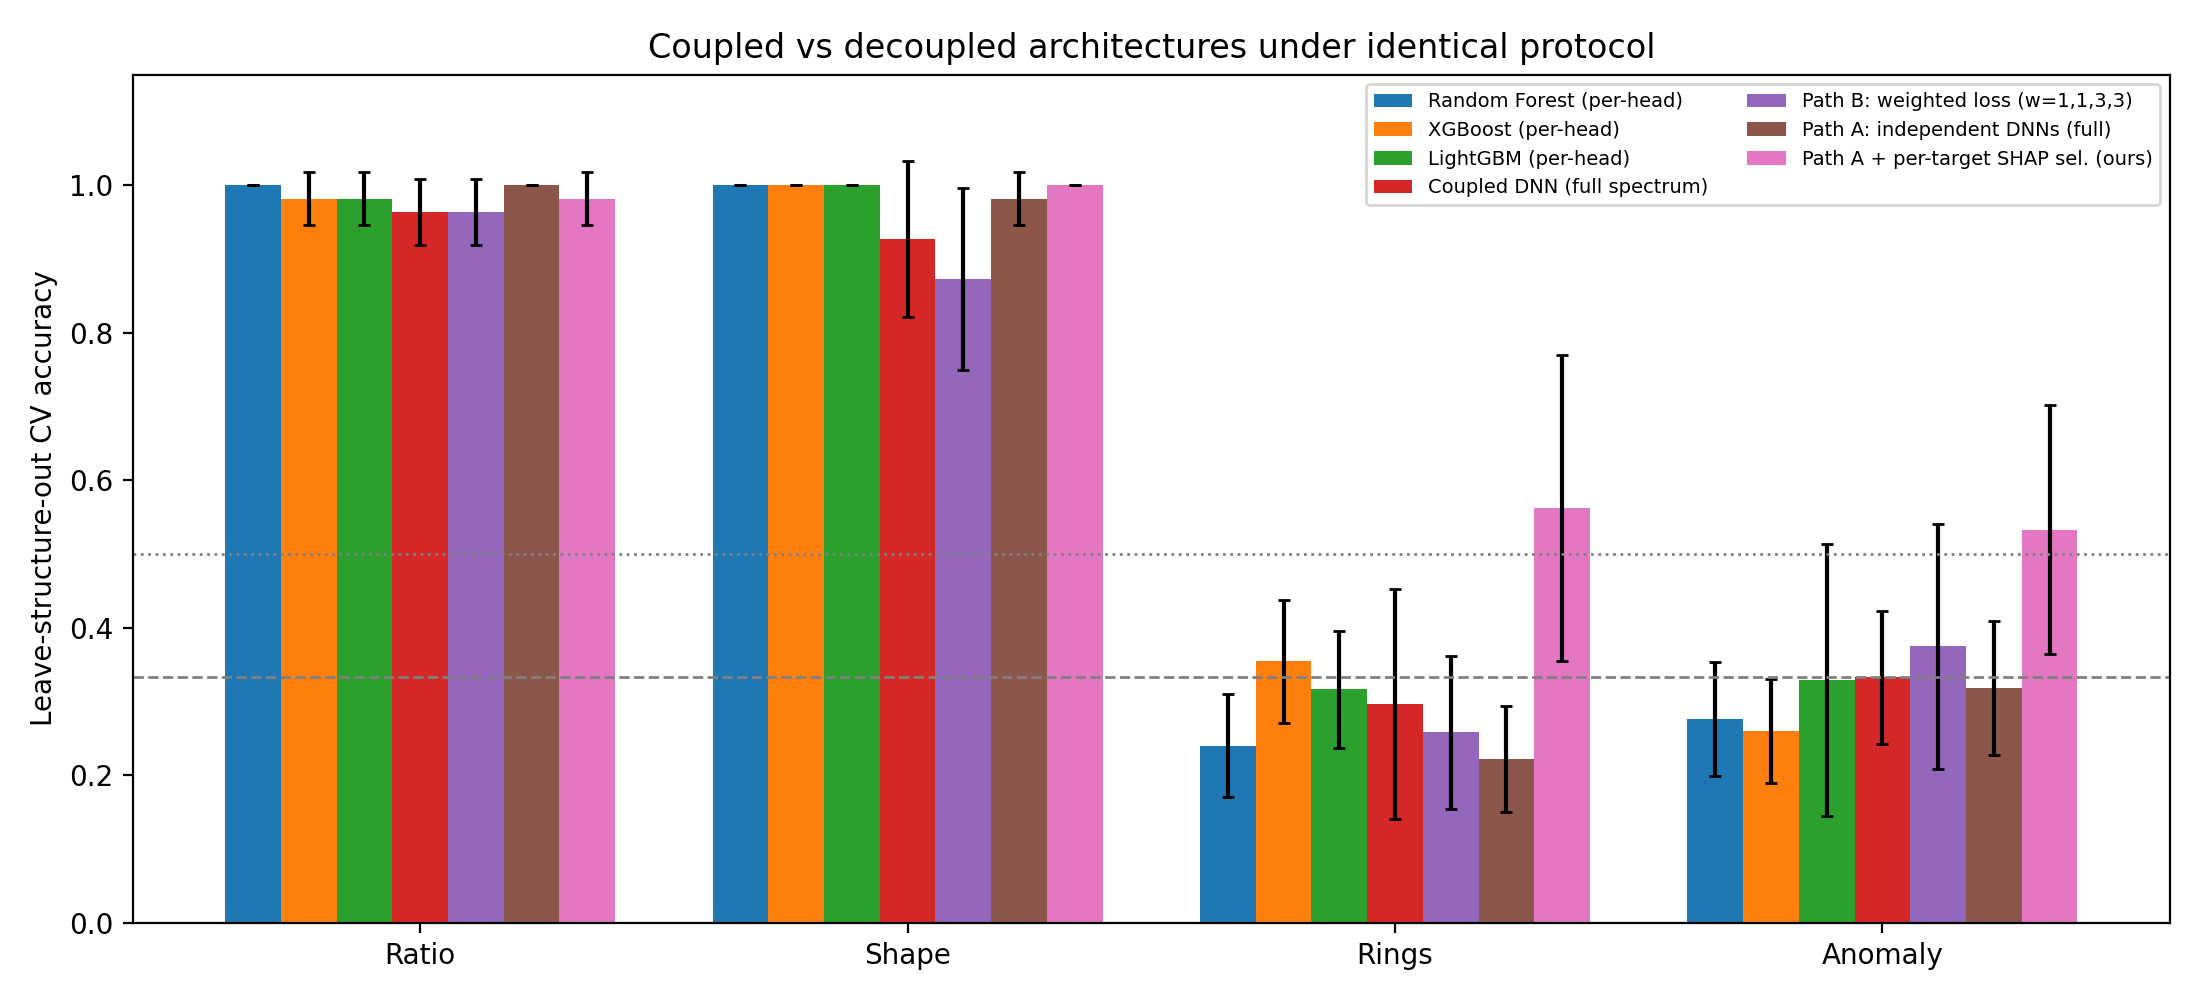

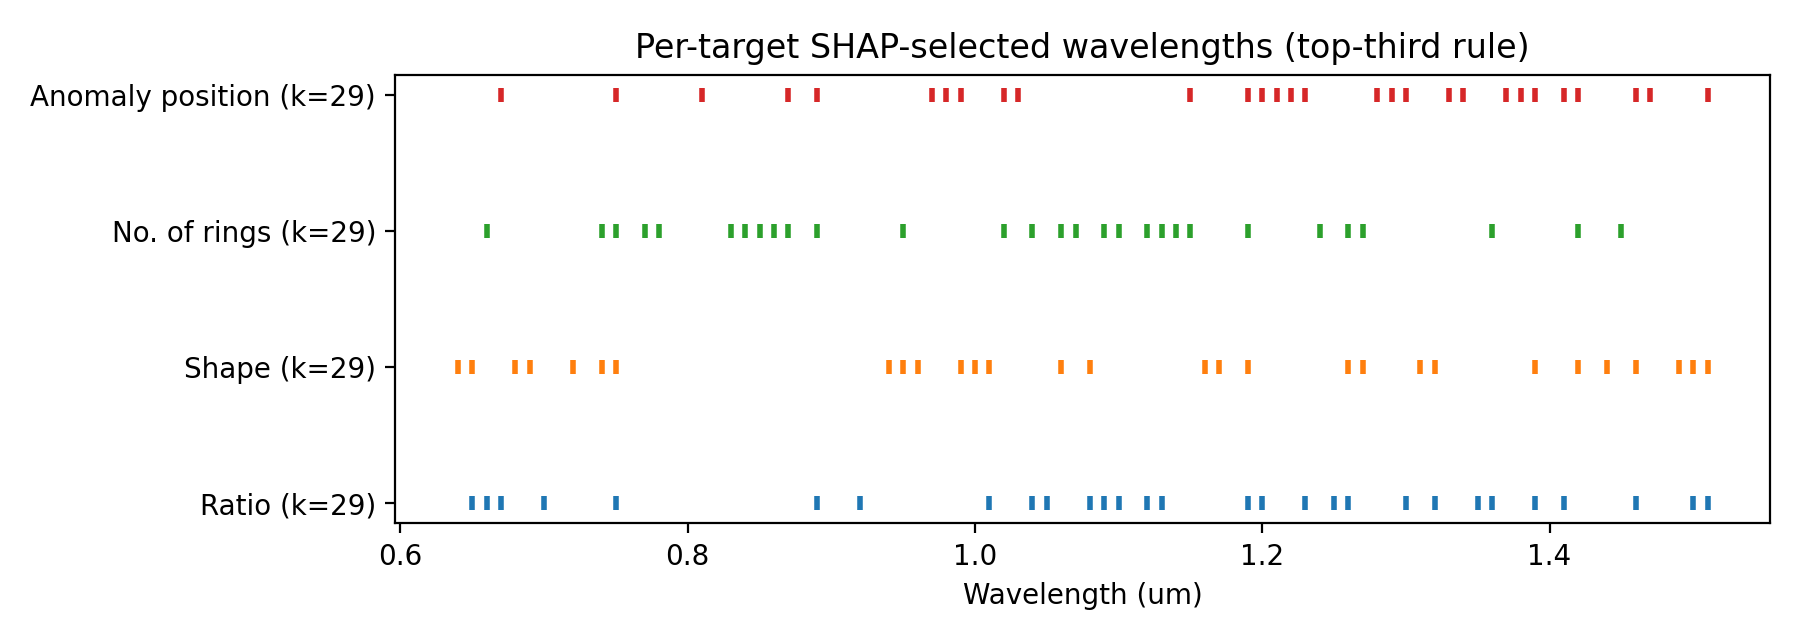

In [11]:
plot_comparison(all_results)
ks = {t: k_third for t in TARGETS}
plot_wavelength_sets(sets, wavelengths, ks)
from IPython.display import Image, display
display(Image(str(OUT_DIR / "fig9_model_comparison.png")))
display(Image(str(OUT_DIR / "fig10_wavelength_sets.png")))

## 3.7 Accuracy vs number of selected wavelengths (Figure 6)
Global-selection k-sweep on the coupled model — shows saturation with a sparse subset.

In [12]:
def dnn_cv(X, y, n_classes, feat_idx=None, seed=0):
    if feat_idx is None:
        feat_idx = np.arange(X.shape[1])
    Xs = X[:, feat_idx]
    gkf = GroupKFold(n_splits=N_FOLDS)
    rng = np.random.default_rng(seed)
    accs = {t: [] for t in TARGETS}
    for tr, va in gkf.split(Xs, groups=np.arange(len(Xs))):
        scaler = StandardScaler().fit(Xs[tr])
        Xtr, Xva = scaler.transform(Xs[tr]), scaler.transform(Xs[va])
        ytr = {t: v[tr] for t, v in y.items()}
        yva = {t: v[va] for t, v in y.items()}
        Xtr_a, ytr_a = augment(Xtr, ytr, N_AUG, NOISE_FRAC, rng)
        model = MultiHeadInverseNet(len(feat_idx), n_classes)
        model = train_one(model, Xtr_a, ytr_a, Xva, yva)
        model.eval()
        with torch.no_grad():
            out = model(torch.tensor(Xva, dtype=torch.float32, device=DEVICE))
        for t in TARGETS:
            pred = out[t.replace(".", "_")].argmax(1).cpu().numpy()
            accs[t].append((pred == yva[t]).mean())
    return {t: (float(np.mean(v)), float(np.std(v))) for t, v in accs.items()}


def k_sweep(X, y, n_classes, wl_rank, n_wl):
    results = {}
    for k in K_GRID_:
        if k is None:
            feat_idx, label = None, n_wl
        else:
            sel = np.sort(wl_rank[:k])
            feat_idx = np.concatenate(
                [r * n_wl + sel for r in range(len(RESPONSES))])
            label = k
        results[label] = dnn_cv(X, y, n_classes, feat_idx)
        print(f"[k-sweep] k={label}: " + ", ".join(
            f"{t}={results[label][t][0]:.3f}" for t in TARGETS))
    return results


def plot_k_sweep(results, n_wl):
    ks = sorted(results.keys())
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for t, c in zip(TARGETS, ["tab:blue", "tab:green", "tab:red", "tab:purple"]):
        means = [results[k][t][0] for k in ks]
        stds = [results[k][t][1] for k in ks]
        ax.errorbar(ks, means, yerr=stds, marker="o", capsize=3, label=t, color=c)
    ax.axhline(1 / 3, ls="--", c="gray", lw=1)
    ax.axhline(1 / 2, ls=":", c="gray", lw=1)
    ax.text(ks[-1], 1 / 3 + .01, "chance (3-class)", ha="right", fontsize=7, c="gray")
    ax.text(ks[-1], 1 / 2 + .01, "chance (binary)", ha="right", fontsize=7, c="gray")
    ax.set_xlabel("Number of selected wavelengths (k)")
    ax.set_ylabel("Leave-structure-out CV accuracy")
    ax.set_title("Accuracy saturates with a sparse wavelength subset")
    ax.set_ylim(0, 1.08)
    ax.legend(fontsize=8, loc="center right")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig6_accuracy_vs_k.png", dpi=200)
    plt.close(fig)


[k-sweep] k=5: Ratio=0.982, Shape=0.927, No. of rings=0.447, Anomaly position=0.313
[k-sweep] k=10: Ratio=0.982, Shape=1.000, No. of rings=0.538, Anomaly position=0.280
[k-sweep] k=20: Ratio=0.982, Shape=0.982, No. of rings=0.558, Anomaly position=0.389
[k-sweep] k=32: Ratio=1.000, Shape=0.982, No. of rings=0.467, Anomaly position=0.375
[k-sweep] k=50: Ratio=0.964, Shape=0.982, No. of rings=0.322, Anomaly position=0.335
[k-sweep] k=88: Ratio=1.000, Shape=1.000, No. of rings=0.260, Anomaly position=0.244


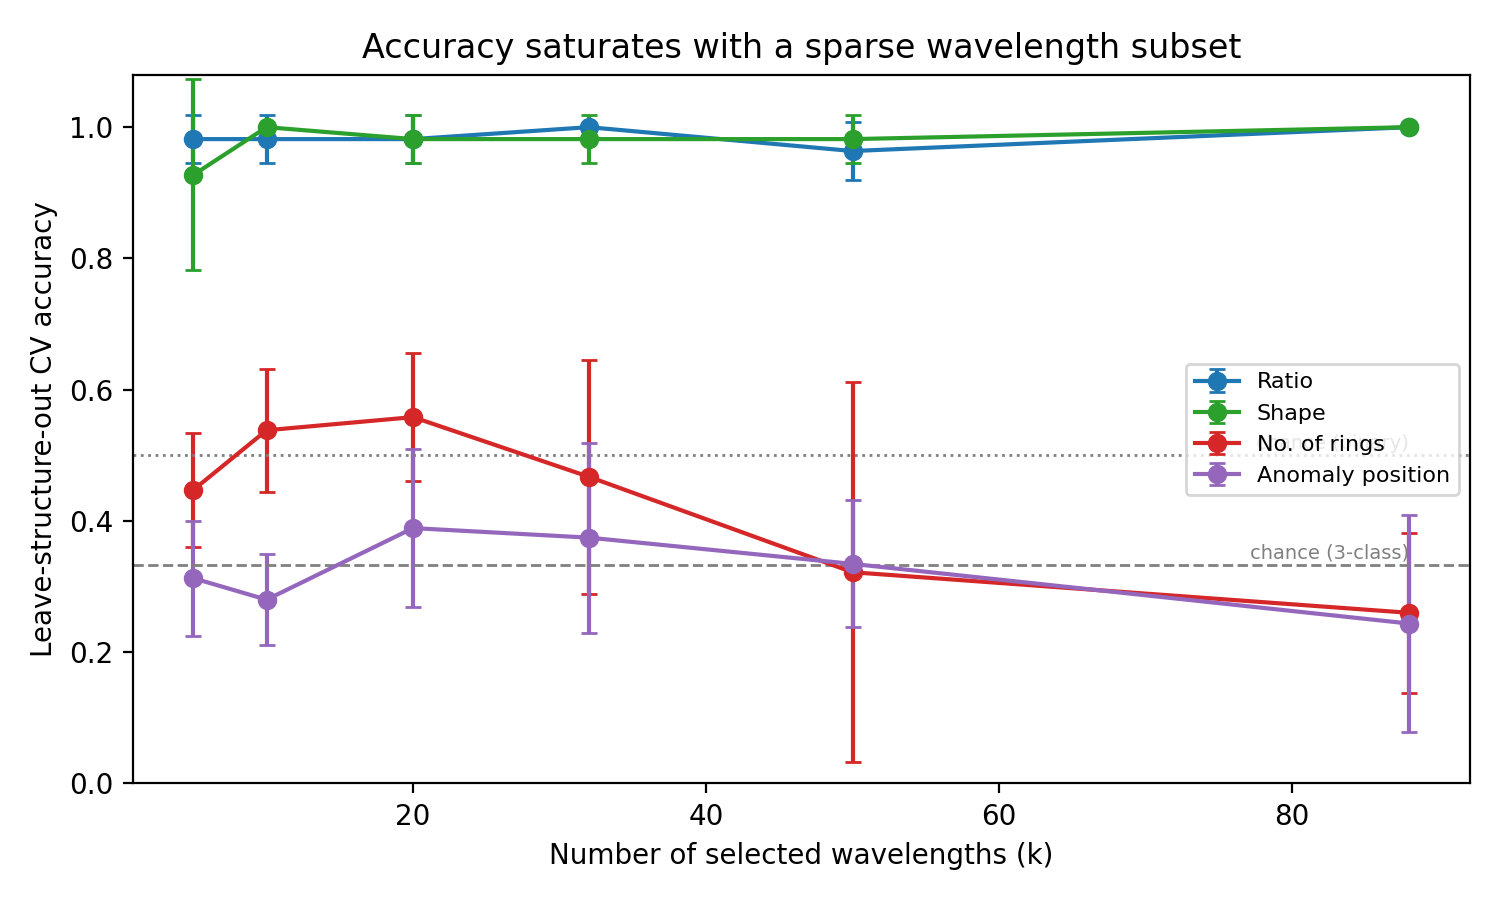

In [13]:
K_GRID_ = [5, 10, 20, 32, 50, None]
global_rank = np.argsort(sum(rankings[t] for t in TARGETS))[::-1]
ksweep = k_sweep(X, y, n_classes, global_rank, n_wl)
plot_k_sweep(ksweep, n_wl)
display(Image(str(OUT_DIR / "fig6_accuracy_vs_k.png")))

## 3.8 Label-permutation tests

In [14]:
def permutation_test(X, y, n_classes, observed):
    rng = np.random.default_rng(7)
    null = {t: [] for t in TARGETS}
    for p in range(N_PERM_):
        y_perm = {t: rng.permutation(v) for t, v in y.items()}
        res = dnn_cv(X, y_perm, n_classes, seed=100 + p)
        for t in TARGETS:
            null[t].append(res[t][0])
        print(f"[perm {p + 1}/{N_PERM_}] " +
              ", ".join(f"{t}={res[t][0]:.3f}" for t in TARGETS))
    pvals = {}
    for t in TARGETS:
        arr = np.asarray(null[t])
        # one-sided p with +1 smoothing (Phipson & Smyth)
        pvals[t] = float((np.sum(arr >= observed[t][0]) + 1) /
                         (N_PERM_ + 1))
    return null, pvals


def plot_permutation(null, observed, pvals):
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=False)
    for ax, t in zip(axes, TARGETS):
        arr = np.asarray(null[t])
        ax.hist(arr, bins=10, color="lightgray", edgecolor="gray",
                label="permuted labels")
        ax.axvline(observed[t][0], color="crimson", lw=2,
                   label=f"observed ({observed[t][0]:.2f})")
        ax.set_title(f"{t}\np = {pvals[t]:.3f}", fontsize=9)
        ax.set_xlabel("CV accuracy", fontsize=8)
        ax.tick_params(labelsize=7)
    axes[0].set_ylabel("count")
    axes[0].legend(fontsize=7)
    fig.suptitle("Label-permutation test (20 permutations, leave-structure-out CV)")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig7_permutation_test.png", dpi=200)
    plt.close(fig)


[perm 1/20] Ratio=0.411, Shape=0.240, No. of rings=0.296, Anomaly position=0.296
[perm 2/20] Ratio=0.647, Shape=0.336, No. of rings=0.331, Anomaly position=0.411
[perm 3/20] Ratio=0.404, Shape=0.296, No. of rings=0.315, Anomaly position=0.276
[perm 4/20] Ratio=0.533, Shape=0.331, No. of rings=0.220, Anomaly position=0.295
[perm 5/20] Ratio=0.538, Shape=0.476, No. of rings=0.256, Anomaly position=0.335
[perm 6/20] Ratio=0.556, Shape=0.293, No. of rings=0.298, Anomaly position=0.222
[perm 7/20] Ratio=0.500, Shape=0.260, No. of rings=0.260, Anomaly position=0.311
[perm 8/20] Ratio=0.444, Shape=0.349, No. of rings=0.255, Anomaly position=0.240
[perm 9/20] Ratio=0.518, Shape=0.295, No. of rings=0.189, Anomaly position=0.331
[perm 10/20] Ratio=0.649, Shape=0.335, No. of rings=0.484, Anomaly position=0.460
[perm 11/20] Ratio=0.504, Shape=0.296, No. of rings=0.349, Anomaly position=0.204
[perm 12/20] Ratio=0.464, Shape=0.351, No. of rings=0.200, Anomaly position=0.316
[perm 13/20] Ratio=0.424,

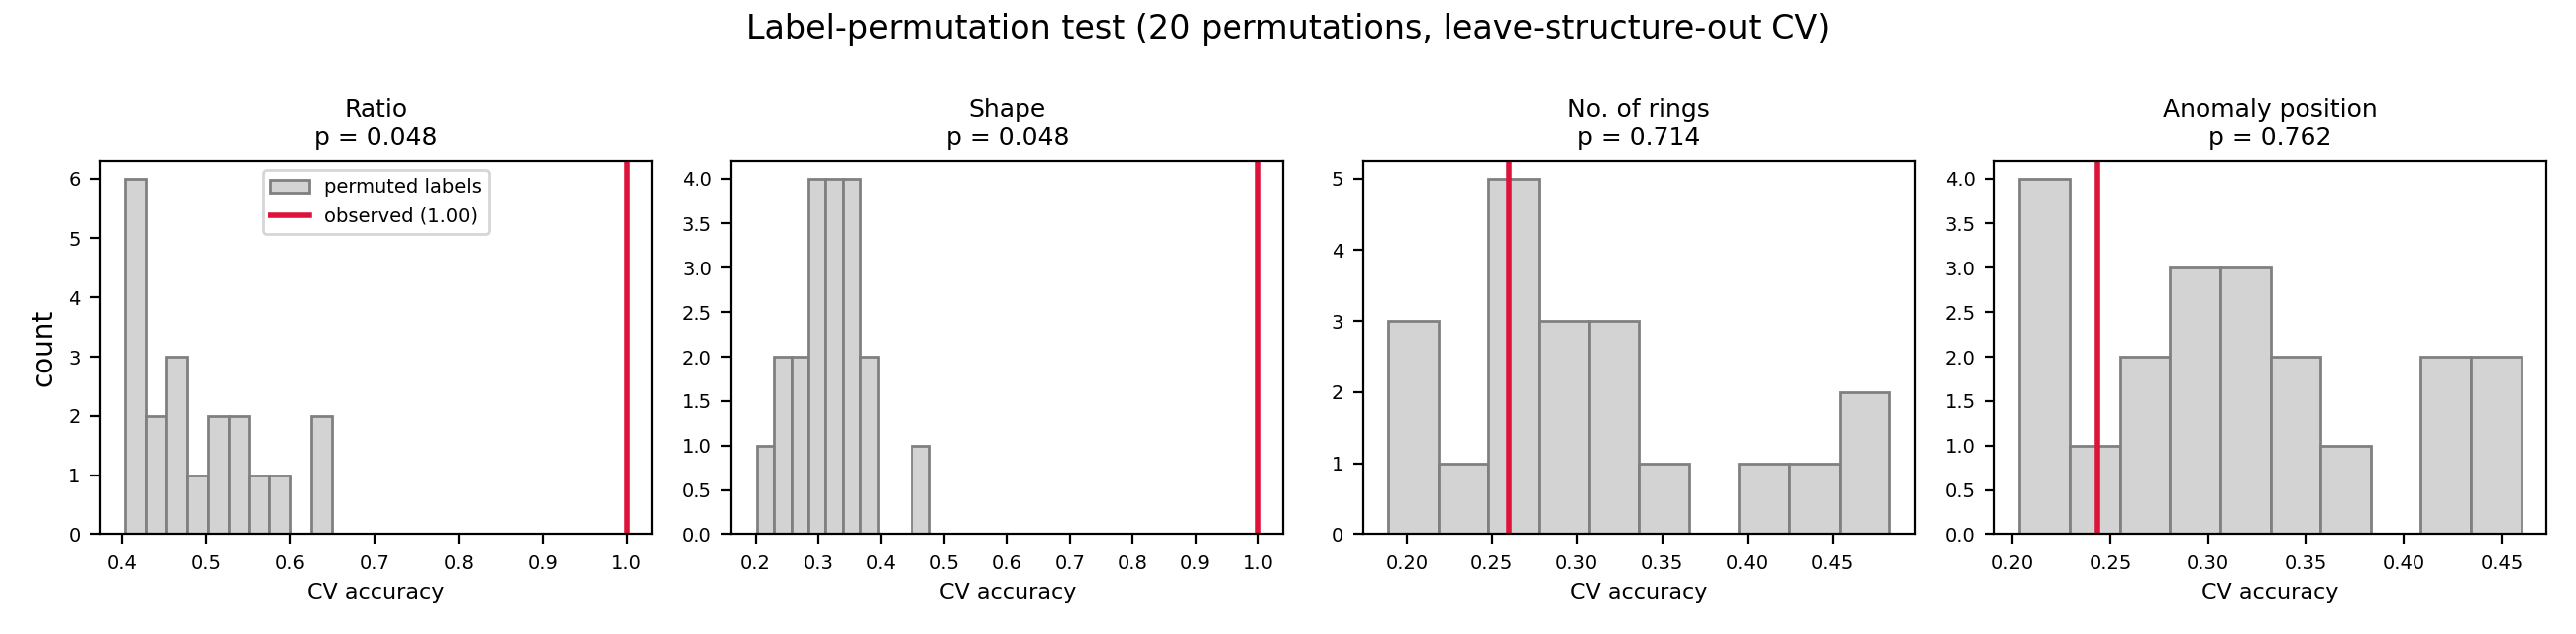

In [15]:
N_PERM_ = 20
observed = ksweep[n_wl]
null, pvals = permutation_test(X, y, n_classes, observed)
plot_permutation(null, observed, pvals)
print("coupled-model p-values:", pvals)
display(Image(str(OUT_DIR / "fig7_permutation_test.png")))

perm 1/12 done
perm 2/12 done
perm 3/12 done
perm 4/12 done
perm 5/12 done
perm 6/12 done
perm 7/12 done
perm 8/12 done
perm 9/12 done
perm 10/12 done
perm 11/12 done
perm 12/12 done


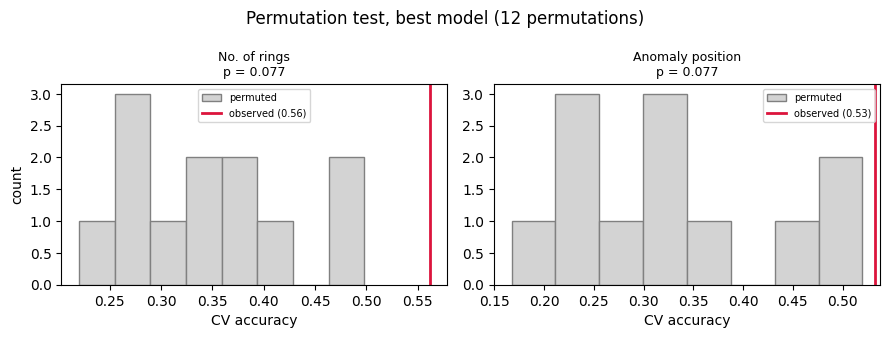

best-model p-values: {'No. of rings': 0.07692307692307693, 'Anomaly position': 0.07692307692307693}


In [16]:
# Fig 12: permutation test for the best model on the hard heads
HARD = ["No. of rings", "Anomaly position"]
rng = np.random.default_rng(11)
perm_null = {t: [] for t in HARD}
for p in range(12):
    for t in HARD:
        y_perm = rng.permutation(y[t])
        acc = cv_single_head(X, y_perm, n_classes[t],
                             feat_idx=feat_idx_for(sets[t], n_wl), seed=200 + p)
        perm_null[t].append(acc[0])
    print(f"perm {p+1}/12 done")

obs_best = {t: all_results["Path A + per-target SHAP sel. (ours)"][t][0] for t in HARD}
pvals_best = {t: float((np.sum(np.asarray(perm_null[t]) >= obs_best[t]) + 1) /
                       (len(perm_null[t]) + 1)) for t in HARD}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, t in zip(axes, HARD):
    ax.hist(perm_null[t], bins=8, color="lightgray", edgecolor="gray", label="permuted")
    ax.axvline(obs_best[t], color="crimson", lw=2, label=f"observed ({obs_best[t]:.2f})")
    ax.set_title(f"{t}\np = {pvals_best[t]:.3f}", fontsize=9)
    ax.set_xlabel("CV accuracy"); ax.legend(fontsize=7)
axes[0].set_ylabel("count")
fig.suptitle("Permutation test, best model (12 permutations)")
fig.tight_layout(); fig.savefig(OUT_DIR / "fig12_perm_best_model.png", dpi=200); plt.show()
print("best-model p-values:", pvals_best)

## 3.9 LIME top-30 overlap (Figure 8) — attribution cross-validation

In [17]:
def lime_top_overlap(model, Xall, feat_names, shap_per_head):
    from lime.lime_tabular import LimeTabularExplainer

    overlaps = {}
    lime_imps = {}
    for t in TARGETS:
        head = t.replace(".", "_")

        def predict_fn(x, head=head):
            with torch.no_grad():
                logits = model(torch.tensor(x, dtype=torch.float32,
                                            device=DEVICE))[head]
                return torch.softmax(logits, 1).cpu().numpy()

        expl = LimeTabularExplainer(Xall, feature_names=feat_names,
                                    discretize_continuous=True,
                                    mode="classification", random_state=0)
        lime_imp = np.zeros(Xall.shape[1])
        rng = np.random.default_rng(2)
        for i in rng.choice(len(Xall), LIME_INSTANCES, replace=False):
            e = expl.explain_instance(Xall[i], predict_fn,
                                      num_features=TOP_K_OVERLAP * 2,
                                      num_samples=LIME_SAMPLES)
            for fidx, w in e.as_map()[e.available_labels()[0]]:
                lime_imp[fidx] += abs(w)
        lime_imps[t] = lime_imp
        top_shap = set(np.argsort(shap_per_head[t])[::-1][:TOP_K_OVERLAP])
        top_lime = set(np.argsort(lime_imp)[::-1][:TOP_K_OVERLAP])
        inter = len(top_shap & top_lime)
        overlaps[t] = {
            "overlap_count": inter,
            "overlap_frac": inter / TOP_K_OVERLAP,
            "jaccard": inter / len(top_shap | top_lime),
            "expected_random": TOP_K_OVERLAP / Xall.shape[1],
        }
        print(f"[LIME-fixed] {t}: top-{TOP_K_OVERLAP} overlap "
              f"{inter}/{TOP_K_OVERLAP} ({inter / TOP_K_OVERLAP:.0%}), "
              f"random baseline {TOP_K_OVERLAP / Xall.shape[1]:.1%}")
    return overlaps, lime_imps


def plot_lime_overlap(overlaps):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    vals = [overlaps[t]["overlap_frac"] for t in TARGETS]
    ax.bar(range(len(TARGETS)), vals, color="darkorange",
           label=f"LIME∩SHAP top-{TOP_K_OVERLAP} overlap")
    ax.axhline(overlaps[TARGETS[0]]["expected_random"], ls="--", c="gray",
               label="random-agreement baseline")
    ax.set_xticks(range(len(TARGETS)), ["Ratio", "Shape", "Rings", "Anomaly"])
    ax.set_ylabel(f"Fraction of shared top-{TOP_K_OVERLAP} features")
    ax.set_ylim(0, 1)
    ax.set_title("SHAP–LIME agreement on decision-critical features")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "fig8_lime_top30_overlap.png", dpi=200)
    plt.close(fig)


In [18]:
# Re-fit a full-spectrum coupled model on all data for attribution
rng = np.random.default_rng(0)
scaler = StandardScaler().fit(X); Xall = scaler.transform(X)
Xa, ya = augment(Xall, y, N_AUG, NOISE_FRAC, rng)
model_full = MultiHeadInverseNet(X.shape[1], n_classes)
model_full = train_one(model_full, Xa, ya, Xall, y); model_full.eval()

MultiHeadInverseNet(
  (trunk): Sequential(
    (0): Linear(in_features=528, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
  )
  (heads): ModuleDict(
    (Ratio): Linear(in_features=64, out_features=2, bias=True)
    (Shape): Linear(in_features=64, out_features=3, bias=True)
    (No_ of rings): Linear(in_features=64, out_features=3, bias=True)
    (Anomaly position): Linear(in_features=64, out_features=3, bias=True)
  )
)

In [19]:
def shap_attribution(model, Xall, n_classes):
    import shap

    class HeadWrapper(nn.Module):
        def __init__(self, m, head):
            super().__init__()
            self.m, self.head = m, head

        def forward(self, x):
            return self.m(x)[self.head]

    Xt = torch.tensor(Xall, dtype=torch.float32, device=DEVICE)
    per_head = {}
    for t in TARGETS:
        wrapper = HeadWrapper(model, t.replace(".", "_")).to(DEVICE).eval()
        expl = shap.GradientExplainer(wrapper, Xt)
        sv = expl.shap_values(Xt)                    # list per class or array
        if isinstance(sv, list):
            mag = np.mean([np.abs(s) for s in sv], axis=0)
        else:                                        # (n, feat, class)
            mag = np.abs(sv).mean(axis=-1)
        per_head[t] = mag.mean(axis=0)               # (n_features,)
    global_imp = np.mean([per_head[t] for t in TARGETS], axis=0)
    return per_head, global_imp


[LIME-fixed] Ratio: top-30 overlap 18/30 (60%), random baseline 5.7%
[LIME-fixed] Shape: top-30 overlap 20/30 (67%), random baseline 5.7%
[LIME-fixed] No. of rings: top-30 overlap 15/30 (50%), random baseline 5.7%
[LIME-fixed] Anomaly position: top-30 overlap 11/30 (37%), random baseline 5.7%


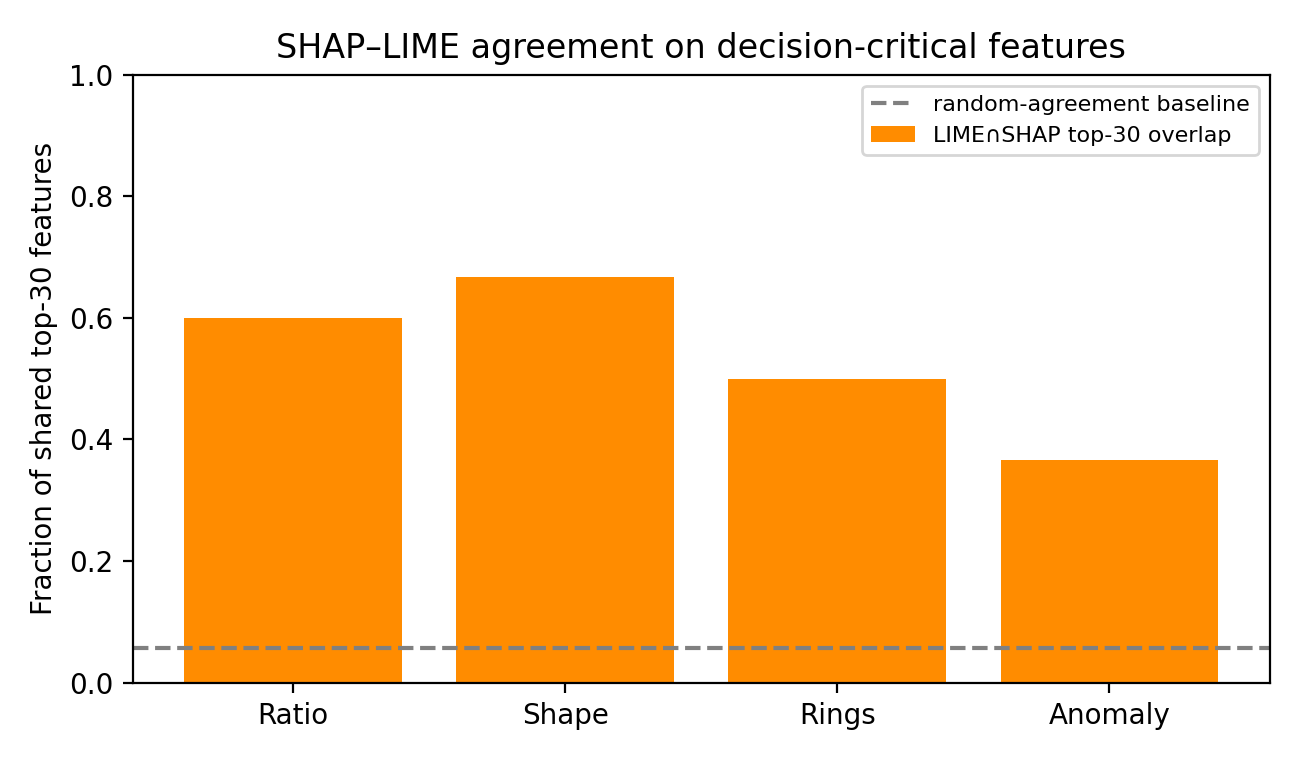

In [20]:


LIME_INSTANCES = 20
LIME_SAMPLES = 5000
TOP_K_OVERLAP = 30
shap_per_head, _ = shap_attribution(model_full, Xall, n_classes)
overlaps, _ = lime_top_overlap(model_full, Xall, feat_names, shap_per_head)
plot_lime_overlap(overlaps)
display(Image(str(OUT_DIR / "fig8_lime_top30_overlap.png")))

## 3.10 Cumulative-mass selection ablation (Figure 11)
Because the SHAP importance spectrum is flat, a 95% cumulative-mass rule keeps
~92% of wavelengths and behaves like no selection; lower masses prune, but
accuracy fluctuations on the hard heads remain within the permutation null.

In [21]:
CUM_GRID = [0.4, 0.5, 0.6, 0.95]
cum_res = {}
for mass in CUM_GRID:
    entry = {"k": {}, "acc": {}}
    for t in TARGETS:
        rank = np.argsort(rankings[t])[::-1]
        cum = np.cumsum(rankings[t][rank]) / rankings[t].sum()
        kk = int(np.searchsorted(cum, mass) + 1)
        sel = np.sort(rank[:kk])
        entry["k"][t] = kk
        entry["acc"][t] = cv_single_head(X, y[t], n_classes[t],
                                         feat_idx=feat_idx_for(sel, n_wl))
    cum_res[mass] = entry
    print(f"mass={mass}:", {t: (entry["k"][t], round(entry["acc"][t][0], 3)) for t in TARGETS})

mass=0.4: {'Ratio': (28, 1.0), 'Shape': (27, 1.0), 'No. of rings': (26, 0.469), 'Anomaly position': (28, 0.502)}
mass=0.5: {'Ratio': (37, 1.0), 'Shape': (35, 1.0), 'No. of rings': (35, 0.542), 'Anomaly position': (36, 0.5)}
mass=0.6: {'Ratio': (45, 0.982), 'Shape': (44, 1.0), 'No. of rings': (43, 0.615), 'Anomaly position': (45, 0.427)}
mass=0.95: {'Ratio': (81, 1.0), 'Shape': (80, 0.982), 'No. of rings': (81, 0.2), 'Anomaly position': (82, 0.355)}


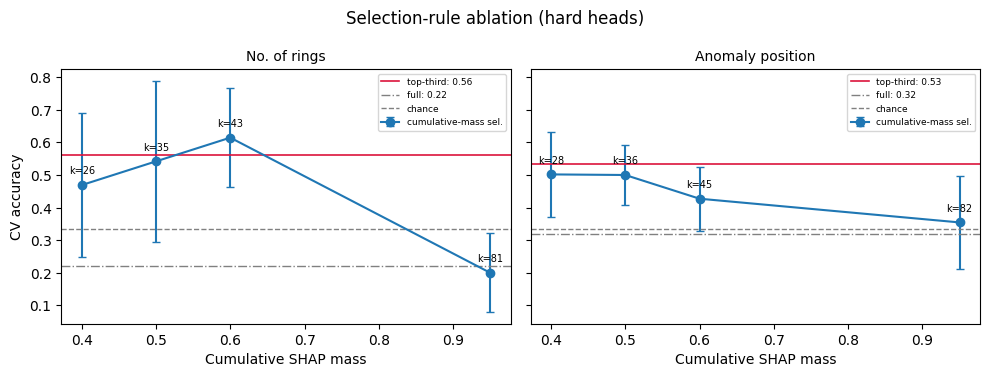

In [22]:
HARD = ["No. of rings", "Anomaly position"]
best_row = all_results["Path A + per-target SHAP sel. (ours)"]
full_row = all_results["Path A: independent DNNs (full)"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, t in zip(axes, HARD):
    xs = sorted(cum_res.keys())
    means = [cum_res[m]["acc"][t][0] for m in xs]
    stds = [cum_res[m]["acc"][t][1] for m in xs]
    ax.errorbar(xs, means, yerr=stds, marker="o", capsize=3, label="cumulative-mass sel.")
    for xi, mi, m in zip(xs, means, xs):
        ax.annotate(f"k={cum_res[m]['k'][t]}", (xi, mi), textcoords="offset points",
                    xytext=(0, 8), fontsize=7, ha="center")
    ax.axhline(best_row[t][0], color="crimson", lw=1.2, label=f"top-third: {best_row[t][0]:.2f}")
    ax.axhline(full_row[t][0], color="gray", ls="-.", lw=1, label=f"full: {full_row[t][0]:.2f}")
    ax.axhline(1/3, color="gray", ls="--", lw=1, label="chance")
    ax.set_title(t, fontsize=10); ax.set_xlabel("Cumulative SHAP mass"); ax.legend(fontsize=6.5)
axes[0].set_ylabel("CV accuracy")
fig.suptitle("Selection-rule ablation (hard heads)")
fig.tight_layout(); fig.savefig(OUT_DIR / "fig11_cummass_sweep.png", dpi=200); plt.show()

## 3.11 Final merged results

In [23]:
final = {
    "comparison_table": {nm: {t: list(rs[t]) for t in TARGETS} for nm, rs in all_results.items()},
    "coupled_perm_pvalues": pvals,
    "best_model_perm_pvalues": pvals_best,
    "cumulative_sweep": {str(m): {"k": e["k"],
        "acc": {t: list(e["acc"][t]) for t in TARGETS}} for m, e in cum_res.items()},
    "k_top_third": k_third,
}
with open(OUT_DIR / "final_results.json", "w") as f:
    json.dump(final, f, indent=2)
print("saved final_results.json")

saved final_results.json
